In [ ]:
3.3: CDF GENERATION

CDF Generation
Total Pixels: 65536

First 10 CDF Values:
Gray Level 0: 0.000000
Gray Level 1: 0.000000
Gray Level 2: 0.000000
Gray Level 3: 0.000000
Gray Level 4: 0.000000
Gray Level 5: 0.000000
Gray Level 6: 0.000000
Gray Level 7: 0.000000
Gray Level 8: 0.000000
Gray Level 9: 0.000000


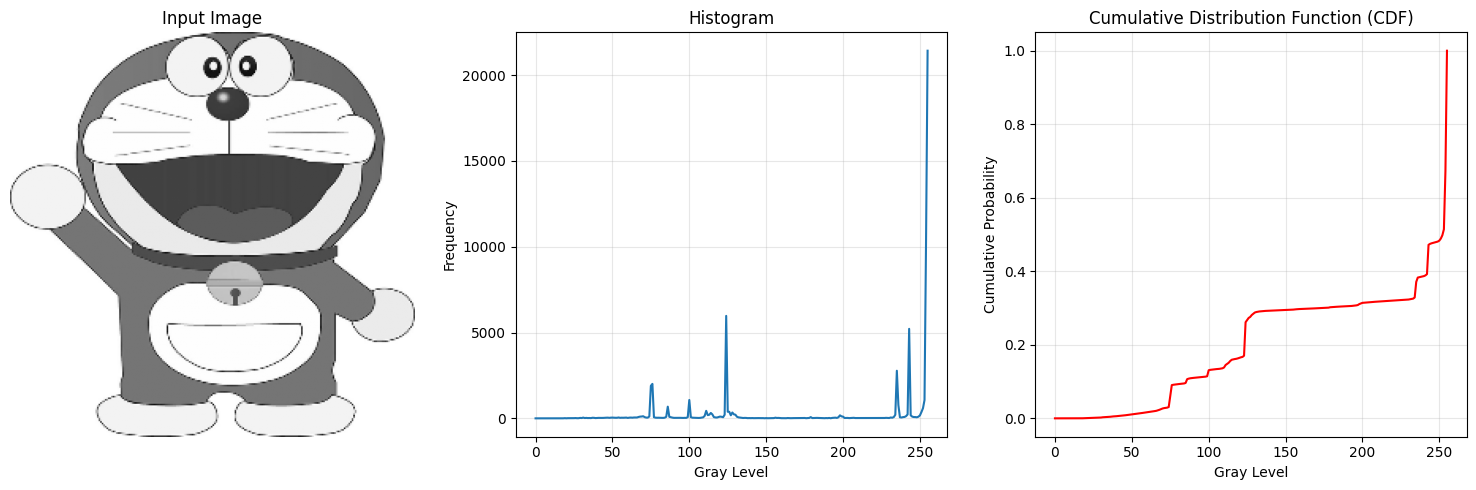


CDF Generation Completed!


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# STEP 1: LOAD UPLOADED IMAGE
filename = list(uploaded.keys())[-1]

image_bytes = np.frombuffer(uploaded[filename], np.uint8)
image = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise ValueError("Image could not be decoded!")

image = cv2.resize(image, (256, 256))

# STEP 2: GENERATE HISTOGRAM
hist = cv2.calcHist([image], [0], None, [256], [0, 256]).flatten()

# STEP 3: GENERATE PDF
pdf = hist / image.size

# STEP 4: GENERATE CDF
cdf = np.cumsum(pdf)

# STEP 5: DISPLAY CDF TABLE
print("CDF Generation")
print("Total Pixels:", image.size)

print("\nFirst 10 CDF Values:")
for i in range(10):
    print(f"Gray Level {i}: {cdf[i]:.6f}")

# STEP 6: DISPLAY IMAGE, HISTOGRAM AND CDF
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.plot(hist)
plt.title("Histogram")
plt.xlabel("Gray Level")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(cdf, color="red")
plt.title("Cumulative Distribution Function (CDF)")
plt.xlabel("Gray Level")
plt.ylabel("Cumulative Probability")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Assignment_3_3_CDF.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nCDF Generation Completed!")